## **Deep Operator Networks Assignment**

### **1.Learning the Derivative Operator**

Design a DeepONet to learn the derivative operator G that maps input functions $u(x)$ to their
derivatives:
$$
\mathcal{G}[u](x)=\frac{du}{dx}, x\in [-1,1]
$$

Consider a family of sine functions as the input function space:
$$
u(x)=Asin(wx+\phi)
$$
The analytical derivative is:

$$
\frac{du}{dx}=Awcos(wx+\phi)
$$

**a)** Design a DeepONet architecture with:
- Branch Network: Input function values $u(x_j)$ at $m = 100$ sensor locations, two hidden layers with 32 neurons each, Tanh activations, output $p = 50$ basis coefficients $b_k(u)$
- Trunk Network: Input query location $y$, two hidden layers with 32 neurons each, Tanh activations, output $p = 50$ basis functions $t_k(y)$

### **Answer:**

In [163]:
import torch.nn as nn
import torch 
import numpy as np
import copy
from tqdm import tqdm
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import time
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [35]:
class deepONet (nn.Module):
    def __init__(self, branch_dim, trunk_dim, p_dim=50, hidden_dim=32):
        super(deepONet, self).__init__()

        self.branch = nn.Sequential(
            nn.Linear(branch_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, p_dim)
        )

        self.trunk = nn.Sequential(
            nn.Linear(trunk_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, p_dim)
        )

    def forward(self, uvals, ylocs):
        branch_out = self.branch(uvals)
        trunk_out = self.trunk(ylocs)
        return torch.einsum('bp,bnp->bn', branch_out, trunk_out)

**b)** Generate $N = 2000$ training functions:
- Amplitude: $A ∼ Uniform(0.5, 2.0)$
- Frequency: $\omega ∼ Uniform(1, 5)$
- Phase: $\phi ∼ Uniform(0, 2\pi)$
- Sample each function at $m = 100$ sensor locations uniformly in $[−1, 1]$
- Compute analytical derivatives: $\frac{du}{dx}=A\omega cos(ωx+\phi)$

### **Answer**

In [36]:
np.random.seed(42)
A = np.random.rand(2000,1) * 1.5 + 0.5
w = np.random.rand(2000,1) * 4 + 1
phi = np.random.rand(2000,1) * 2 * np.pi 
m = np.linspace(-1, 1, 100)
ux = lambda x: A * np.sin(w * x + phi)
dudx = lambda x: A * w * np.cos(w * x + phi)

**c)** Implement the data loss function:
$$
\mathcal{L}_{data}=\frac{1}{N \cdot P}\sum_{i=1}^{N}\sum_{j=1}^{P}\left|\mathcal{G}_{\theta}(u^{(i)})(y_j)-\frac{du^{(i)}}{dx}(y_j)\right|^2
$$
### **Answer**

In [37]:
def loss_func(model, u_train, y_train, s_train, batch_size, optimizer):
    running = 0.0
    order = torch.randperm(len(u_train))
    for i in range(0, len(u_train), batch_size):
        idx = order[i:i+batch_size]
        u_batch = u_train[idx]
        y_batch = y_train[idx].unsqueeze(-1)
        s_batch = s_train[idx]
        s_pred = model(u_batch, y_batch)
        loss = nn.functional.mse_loss(s_pred, s_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(idx)
    train_loss = running / len(u_train)
    return train_loss, optimizer

**d)** Train using 80-10-10 train-validation-test split, batch size 128, Adam optimizer (lr = 10−2), ReduceLROnPlateau scheduler (patience=50, factor=0.5), early stopping (patience=100), maximum 500 epochs.

### **Answer**

In [38]:
def train_model(model, U_train, Y_train, S_train, batch_size=128, lr=1e-2, epochs=500, 
                sched_patience=50, sched_factor=0.5, es_patience=100):
    N = len(U_train)
    perm = torch.randperm(N)
    n_train, n_val = int(0.8*N), int(0.1*N)
    tr_idx = perm[:n_train]
    va_idx = perm[n_train:n_train+n_val]
    te_idx = perm[n_train+n_val:]

    U_tr, Y_tr, S_tr = U_train[tr_idx], Y_train[tr_idx], S_train[tr_idx]
    U_va, Y_va, S_va = U_train[va_idx], Y_train[va_idx], S_train[va_idx]
    U_te, Y_te, S_te = U_train[te_idx], Y_train[te_idx], S_train[te_idx]
    optimizer = torch.optim.Adam(model.parameters(),lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=sched_patience, factor=sched_factor)
    
    pbar = tqdm(range(epochs), desc="Training")
    
    losses = []
    best_val, best_state, bad_epoch = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        train_loss, optimizer = loss_func(model, U_tr, Y_tr, S_tr, batch_size, optimizer)
        
        model.eval()
        with torch.no_grad():
            val_loss = nn.functional.mse_loss(model(U_va, Y_va.unsqueeze(-1)), S_va).item()
        scheduler.step(val_loss)
        losses.append(train_loss)
        
        if (epoch+1) % 100 == 0:
            pbar.set_postfix({
                "train": f"{train_loss:.3e}", "val": f"{val_loss:.3e}",
                'LR': f'{scheduler.get_last_lr()[0]:.2e}'
            })
            pbar.update(100) 
        if val_loss < best_val:
            best_val, bad_epoch = val_loss, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epoch += 1
            if bad_epoch >= es_patience:
                print(f"Early stopping at epoch {epoch+1}")
                break
    print("Training completed!")
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_loss = nn.functional.mse_loss(model(U_te, Y_te.unsqueeze(-1)), S_te).item()
    print(f"Best val {best_val: .3e} | Test MSE {test_loss:.3e}")
    return losses, model

In [39]:
model = deepONet(branch_dim = 100, trunk_dim = 1)
U_train = ux(m)
U_train_tensor = torch.tensor(U_train, dtype=torch.float32)
Y_train = np.linspace(-1,1,200)
Y_train_tensor = torch.tensor(Y_train, dtype=torch.float32)
Y_train_tensor = Y_train_tensor.unsqueeze(0).expand(len(U_train),-1)
S_train = dudx(Y_train)
S_train_tensor = torch.tensor(S_train, dtype=torch.float32)
losses, trained_model = train_model(model, U_train_tensor, Y_train_tensor, S_train_tensor)



Training:  20%|██        | 100/500 [00:15<00:01, 388.52it/s, train=4.140e-02, val=nan, LR=5.00e-03]

Training:   0%|          | 0/500 [00:20<?, ?it/s, train=3.807e-02, val=3.600e-02, LR=1.00e-02]

Training:  20%|██        | 100/500 [00:20<01:20,  4.97it/s, train=3.807e-02, val=3.600e-02, LR=1.00e-02]

Training:  20%|██        | 100/500 [00:40<01:20,  4.97it/s, train=1.005e-01, val=6.718e-02, LR=1.00e-02]

Training:  40%|████      | 200/500 [00:40<01:01,  4.92it/s, train=1.005e-01, val=6.718e-02, LR=1.00e-02]

Training:  40%|████      | 200/500 [01:02<01:01,  4.92it/s, train=4.526e-03, val=5.662e-03, LR=5.00e-03]

Training:  60%|██████    | 300/500 [01:02<00:41,  4.78it/s, train=4.526e-03, val=5.662e-03, LR=5.00e-03]

Training:  60%|██████    | 300/500 [01:25<00:41,  4.78it/s, train=2.765e-03, val=2.769e-03, LR=2.50e-03]

Training:  80%|████████  | 400/500 [01:25<00:21,  4.57it/s, train=2.765e-03, val=2.769e-03, LR=2.50e-03]

Training:  80%|████████  | 400/500 [01:48<00:21,  4.57it/s,

Training completed!
Best val  1.903e-03 | Test MSE 1.892e-03


**c)** Analyze the learned basis functions:
- Visualize the first 8 trunk network basis functions $t_k(y)$
- Test specific cases: $u(x) = sin(x)$, $u(x) = sin(2x)$, $u(x) = 2 sin(3x + \pi/4)$
- Plot predictions vs. analytical derivatives for these cases
- Explain how the branch network encodes frequency and amplitude information

### **Answer**

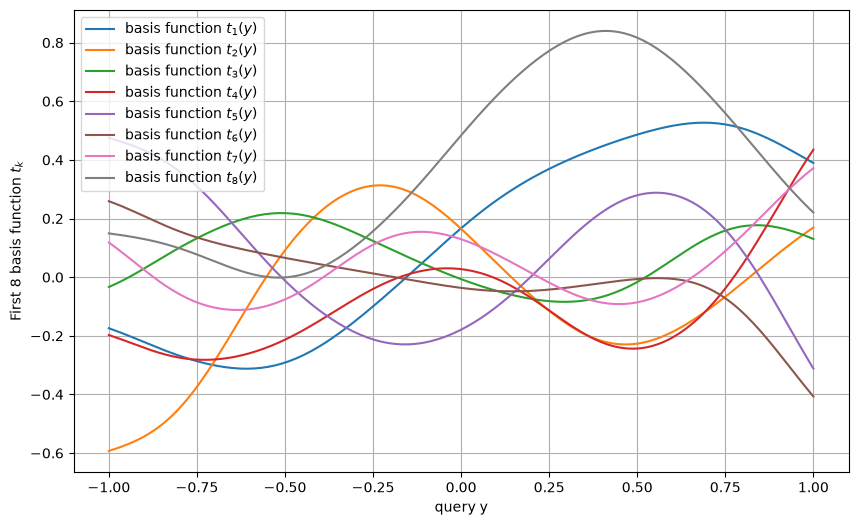

In [19]:
model.eval()
y_grid = torch.linspace(-1,1,200)
with torch.no_grad():
    trunk_out = trained_model.trunk(y_grid.unsqueeze(-1)).numpy()
fig, ax = plt.subplots(1,1,figsize=(10,6))
for i in range(8):
    ax.plot(Y_train, trunk_out[:,i], label=f'basis function $t_{i+1}(y)$')
ax.grid(True)
ax.set_xlabel('query y')
ax.set_ylabel('First 8 basis function $t_k$')
ax.legend()
plt.show()

In [31]:
A = np.array([1,1,2]).reshape(3,1)
w = np.array([1,2,3]).reshape(3,1)
phi = np.array([0,0,np.pi/4]).reshape(3,1)
ux = lambda x: A * np.sin(w * x + phi)
dudx = lambda x: A * w * np.cos(w * x + phi)

In [40]:
U_test = ux(m)
U_test_tensor = torch.tensor(U_test, dtype=torch.float32)
Y_test = np.linspace(-1,1,200)
Y_test_tensor = torch.tensor(Y_test, dtype=torch.float32)
Y_test_tensor = Y_test_tensor.unsqueeze(0).expand(len(U_test),-1)

trained_model.eval()
with torch.no_grad():
    pred = trained_model(U_test_tensor, Y_test_tensor.unsqueeze(-1)).numpy()

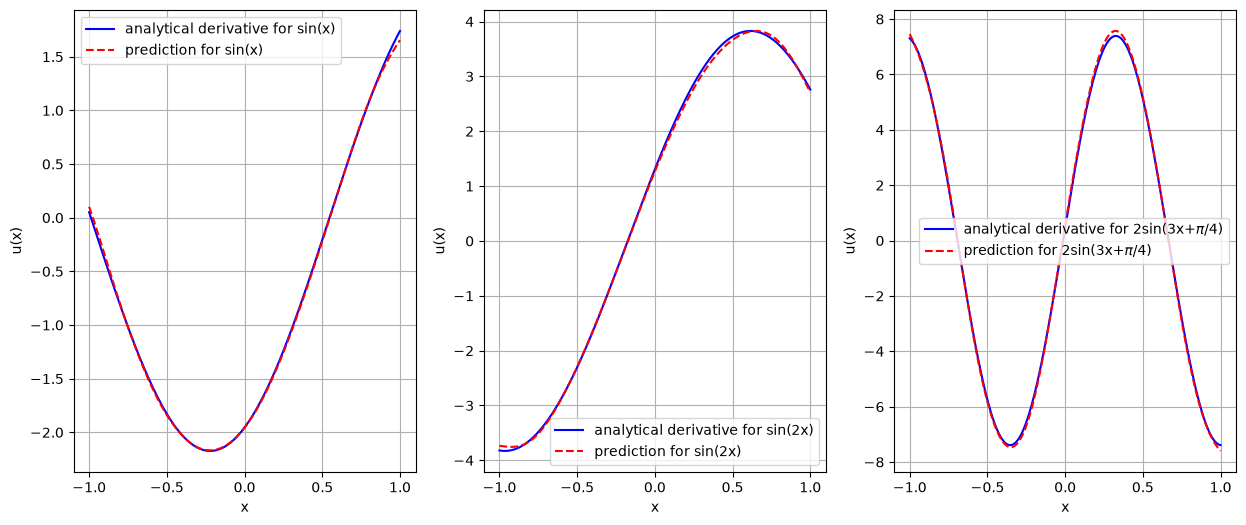

In [45]:
fig, ax = plt.subplots(1,3,figsize=(15,6))
func = ['sin(x)', 'sin(2x)', '2sin(3x+$\pi/4$)']
for i in range(len(func)):
    ax[i].plot(Y_test, dudx(Y_test)[i], label=f'analytical derivative for {func[i]}', color='b')
    ax[i].plot(Y_test, pred[i], label=f'prediction for {func[i]}', color='r', linestyle='--')
    ax[i].grid(True)
    ax[i].legend()
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('u(x)')

- Explain how the branch network encodes frequency and amplitude information

When the input function’s amplitude changes, the derivative’s amplitude also changes correspondingly. The branch network must carry this amplitude information in its output coefficients for the learned basis functions, so the reconstructed output also changes following the change in the input function.

Regarding frequency information, the values sampled at the same sensor locations show different oscillation patterns when the input frequency changes. The branch network must then produce new coefficients that combine the learned basis functions from the trunk network into an output with the corresponding oscillation pattern. For differentiation, these coefficients must also account for the change in derivative amplitude caused by the input frequency.

**f)** Evaluate generalization:
- Compute relative $L^{2}$ error on test set:
$
\frac{\left|\left| u^{'}_{pred}-u^{'}_{true} \right|\right|_{2}}{\left|\left| u^{'}_{true}\right|\right|_2}
$
- Plot predictions vs. true derivatives for 6 test samples
- Report mean and standard deviation of test errors

### **Answer**

In [78]:
np.random.seed(42)
A = np.random.rand(6,1) * 1.5 + 0.5
w = np.random.rand(6,1) * 4 + 1
phi = np.random.rand(6,1) * 2 * np.pi 
m = np.linspace(-1, 1, 100)
ux = lambda x: A * np.sin(w * x + phi)
dudx = lambda x: A * w * np.cos(w * x + phi)
U_te = torch.tensor(ux(m), dtype=torch.float32)
y = np.linspace(-1, 1,200)
Y_te = torch.linspace(-1, 1, 200).unsqueeze(0).expand(len(U_te),-1)
S_te = torch.tensor(dudx(y))

trained_model.eval()
with torch.no_grad():
    pred = trained_model(U_te, Y_te.unsqueeze(-1))

rel_error = torch.norm(pred-S_te) / torch.norm(S_te)
print(f"Relative L2 error on test set is: {rel_error*100:.2f}%")

Relative L2 error on test set is: 1.29%


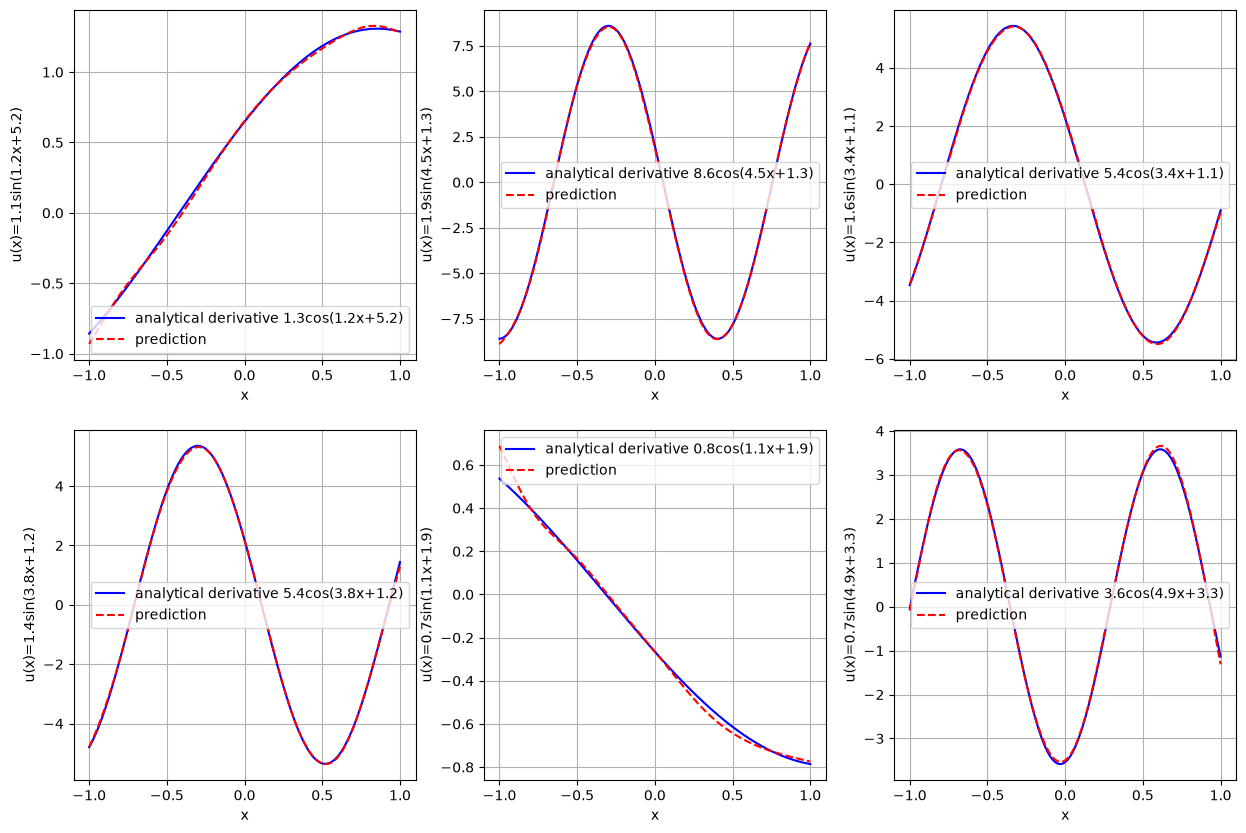

In [81]:
fig, axes = plt.subplots(2,3, figsize=(15,10))
axes = axes.ravel()
for i, ax in enumerate(axes):
    ax.plot(y, dudx(y)[i], label=f'analytical derivative {A[i,0]*w[i,0]:.1f}cos({w[i,0]:.1f}x+{phi[i,0]:.1f})', color='b')
    ax.plot(y, pred.numpy()[i], label= 'prediction', color='r', linestyle='--')
    ax.grid(True)
    ax.set_xlabel('x')
    ax.set_ylabel(f'u(x)={A[i,0]:.1f}sin({w[i,0]:.1f}x+{phi[i,0]:.1f})')
    ax.legend()

In [89]:
test_error = pred-S_te
print(f'The mean of the test error is: {test_error.mean().item():.2e}, and the standard deviation is: {test_error.std().item():.2e}')

The mean of the test error is: -9.72e-03, and the standard deviation is: 4.28e-02


### **2. 1D Advection-Diffusion Equation**

Learn the solution operator for the steady-state advection-diffusion equation:
$$
\nu\frac{d^2u}{dx^2}-c\frac{du}{dx}=f(x), x\in[0,1]
$$

with Dirichlet boundary conditions $u(0)=u(1)=0$, diffusion coefficient $\nu=0.01$, and advection velocity $c=1.0$

**a)** Generate training data:
- Create $N=1000$ source functions using Fourier series:
$$
f(x)=\sum_{n=1}^{4}c_n sin(n\pi x), c_n \sim\mathcal{N}(0,(1/n)^2)
$$
- For each $f(x)$, solve the BVP numerically using finite difference with $n_x=100$ grid points.
- Discretizing using central differences for diffusion and upwind for advection:
$$
\nu\frac{u_{i-1}-2u_{i}+u_{i+1}}{\Delta x^2}-c\frac{u_i-u_{i-1}}{\Delta x}=f_i
$$
### **Answer**

In [111]:
np.random.seed(42)
cn = np.random.randn(1000,1)*(1/n)
f = lambda x: sum([cn*np.sin(n*np.pi*x) for n in range(1,5)])

In [113]:
x = np.linspace(0,1,100)
F = f(x)

In [164]:
nu, c = 0.01, 1.0
dx = x[1] - x[0]
u = np.zeros(F.shape)
t0 = time.perf_counter()
for it in range(1,20001):
    u_new = u.copy()
    u_new[:,1:-1] = (dx**2 * F[:, 1:-1] - (nu+c*dx) * u[:,0:-2] - nu * u[:, 2:]) / (-2*nu-c*dx)
    err = np.max(np.abs(u_new - u))
    u = u_new
    if err < 1e-12:
        break
    if it % 100 == 0:
        print(f'Iteration {it}/20000, current error is: {err}')
elapsed = time.perf_counter() - t0
print(f"Solving time: {elapsed:.1f} s ({elapsed/60:.2f} min)")

Iteration 100/20000, current error is: 0.00765636044104584
Iteration 200/20000, current error is: 0.006162025663498882
Iteration 300/20000, current error is: 0.0021192237998610697
Iteration 400/20000, current error is: 8.44580489043345e-05
Iteration 500/20000, current error is: 1.0959146719002888e-06
Iteration 600/20000, current error is: 7.847243077563348e-09
Iteration 700/20000, current error is: 3.9924730188545254e-11
Solving time: 0.5 s (0.01 min)


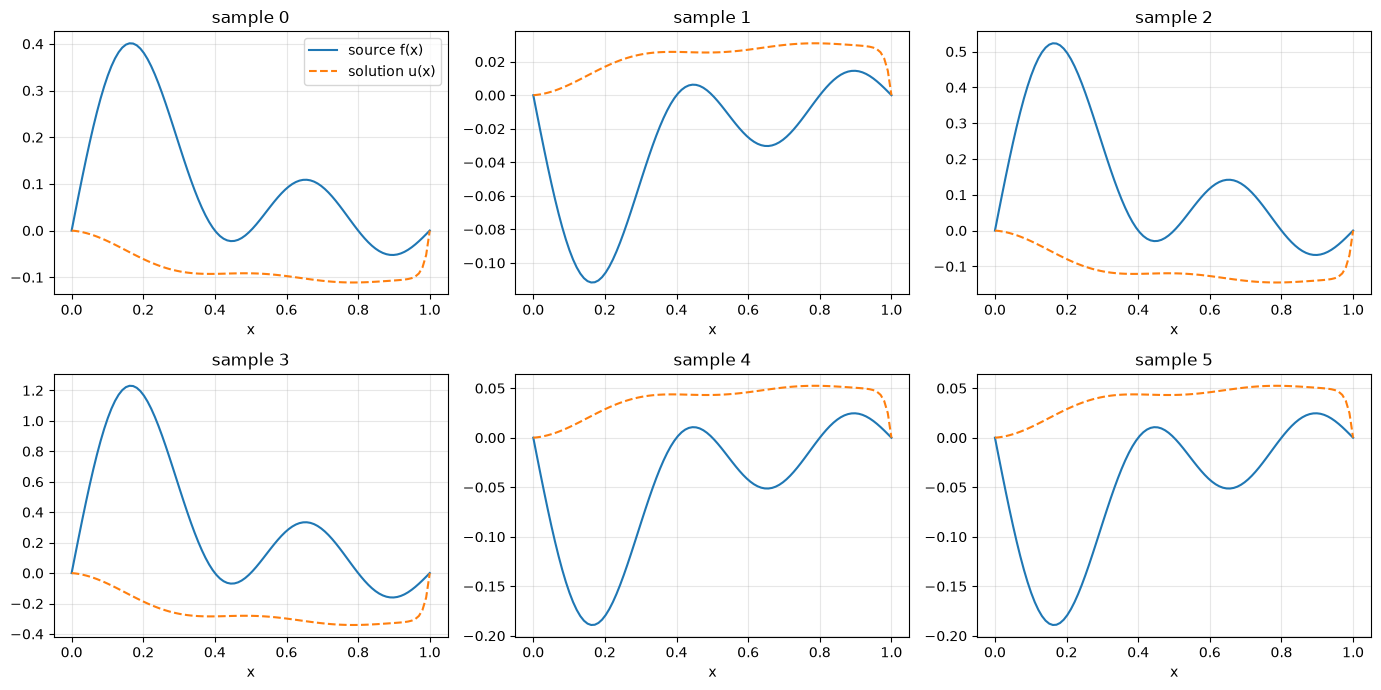

In [132]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, i in zip(axes.ravel(), range(6)):          # first 6 samples
    ax.plot(x, F[i], label='source f(x)')
    ax.plot(x, u[i], '--', label='solution u(x)')
    ax.set_title(f'sample {i}')
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**b)** Design a DeepONet with:
- Branch network: source function values at 100 points, three hidden layers (128 neurons), Tanh, output 100 coefficients
- Trunk network: spatial coordinate, three hidden layers (128 neurons), Tanh, output 100 basis functions
### **Answer**

In [161]:
class DeepONet (nn.Module):
    def __init__(self, branch_dim=100, trunk_dim=1, p_dim=100, hidden_dim=128, hidden_depth=3):
        super(DeepONet, self).__init__()
        layer_branch = [nn.Linear(branch_dim, hidden_dim),nn.Tanh()]
        layer_trunk = [nn.Linear(trunk_dim, hidden_dim),nn.Tanh()]
        for _ in range(hidden_depth-1):
            layer_branch.append(nn.Linear(hidden_dim, hidden_dim))
            layer_branch.append(nn.Tanh())
            layer_trunk.append(nn.Linear(hidden_dim, hidden_dim))
            layer_trunk.append(nn.Tanh())
        layer_branch.append(nn.Linear(hidden_dim, p_dim))
        layer_trunk.append(nn.Linear(hidden_dim, p_dim))
        self.branch = nn.Sequential(*layer_branch)
        self.trunk = nn.Sequential(*layer_trunk)
    def forward(self, uval, yval):
        branch_out = self.branch(uval)
        trunk_out = self.trunk(yval)
        return torch.einsum('bp,bnp->bp',branch_out,trunk_out)

**c)** Normalize targets using training statistics: $\tilde{u} = (u − \mu u)/\sigma u$

In [171]:
mu_u = np.mean(u,0)
std_u = np.std(u,0)
u_norm = np.zeros(u.shape)
u_norm[:,1:-1] = (u[:,1:-1] - mu_u[1:-1]) / std_u[1:-1]

**d)** Train using 80-20 split, batch size 64, Adam (lr = 10−3, weight decay 10−5), cosine annealing scheduler, 3000 epochs.

In [189]:
def train_model(model, U_train, Y_train, S_train, batch_size=64, lr=1e-3, weight_decay=1e-5, epochs=3000):
    N = len(U_train)
    perm = torch.randperm(N)
    n_train = int(0.8*N)
    idx_train = perm[:n_train]
    idx_val = perm[n_train:]

    U_tr, Y_tr, S_tr = U_train[idx_train], Y_train[idx_train], S_train[idx_train]
    U_va, Y_va, S_va = U_train[idx_val], Y_train[idx_val], S_train[idx_val]

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    pbar = tqdm(range(epochs), desc="Training")
    
    losses = []
    best_val, best_state, bad_epoch = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(U_tr))
        running = 0.0
        for i in range(0, len(U_tr), batch_size):
            optimizer.zero_grad()
            idx = order[i:i+batch_size]
            S_pred = model(U_tr[idx], Y_tr[idx].unsqueeze(-1))
            loss = nn.functional.mse_loss(S_pred, S_tr[idx])
            loss.backward()
            optimizer.step()
            running += loss.item()*len(idx)
        train_loss = running / len(U_tr)
        model.eval()
        with torch.no_grad():
            val_loss = nn.functional.mse_loss(model(U_va, Y_va.unsqueeze(-1)), S_va).item()
        scheduler.step()
        losses.append(val_loss)

        if epoch % 100 == 0:
            pbar.set_postfix({
                "Train_loss": f'{train_loss:.3e}', "Val_loss": f'{val_loss:.3e}',
                "lr": f'{scheduler.get_last_lr()[0]:.3e}'
            })
            pbar.update(200)
            
        if best_val > val_loss:
            best_val = val_loss
            bad_epoch = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epoch += 1
            if bad_epoch > 100:
                print(f'Early stop at {epoch} epochs!')
                break
    print("Training complete!")
    model.load_state_dict(best_state)
    return losses, model, U_va, Y_va, S_va

**e)** Evaluate: compute relative $L^2$ error, plot 6 test cases (source and solution), visualize 8 learned basis functions.
### **Answer**

In [183]:
U_train_tensor = torch.tensor(F, dtype=torch.float32)
Y_train = np.linspace(0,1,100)
Y_train_tensor = torch.tensor(Y_train, dtype=torch.float32)
Y_train_tensor_expand = Y_train_tensor.unsqueeze(0).expand(len(F),-1)
S_train_tensor = torch.tensor(u_norm, dtype=torch.float32)
model = DeepONet()
t0 = time.perf_counter()
losses, trained_model_2, U_va, Y_va, S_va = train_model(model,U_train_tensor,Y_train_tensor_expand,S_train_tensor)
elapsed = time.perf_counter() - t0
print(f"Training time: {elapsed:.1f} s ({elapsed/60:.2f} min)")


Training:  27%|██▋       | 800/3000 [01:54<05:14,  7.00it/s, Train_loss=7.745e-04, Val_loss=2.117e-03, lr=9.756e-04]

Early stop at 374 epochs!
Training complete!
Training time: 114.3 s (1.90 min)


relative L2 error is: 1.68%


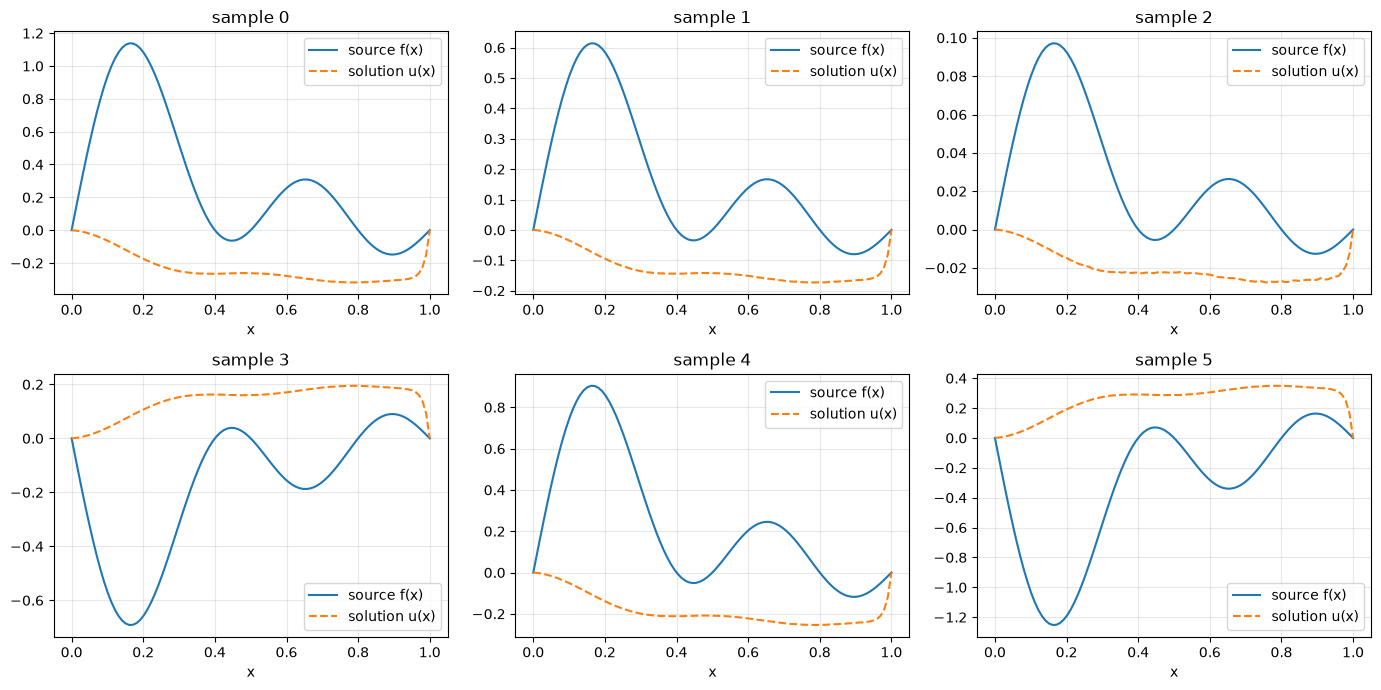

In [190]:
with torch.no_grad():
    s_pred = trained_model_2(U_va, Y_va.unsqueeze(-1)).numpy()
pred_u = np.zeros_like(s_pred)
pred_u[:, 1:-1] = s_pred[:, 1:-1] * std_u[1:-1] + mu_u[1:-1]
s_va = np.zeros_like(S_va)
s_va[:, 1:-1] = S_va.numpy()[:, 1:-1] * std_u[1:-1] + mu_u[1:-1]
rel_error = torch.norm(torch.tensor(pred_u - s_va)) / torch.norm(torch.tensor(s_va))
print(f"relative L2 error is: {rel_error*100:.2f}%")
fig, axes = plt.subplots(2,3, figsize=(14,7))
axes = axes.ravel()
for i, ax in enumerate(axes):
    ax.plot(Y_train, U_va[i], label='source f(x)')
    ax.plot(Y_train, pred_u[i], '--', label='solution u(x)')
    ax.set_title(f'sample {i}')
    ax.set_xlabel('x')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

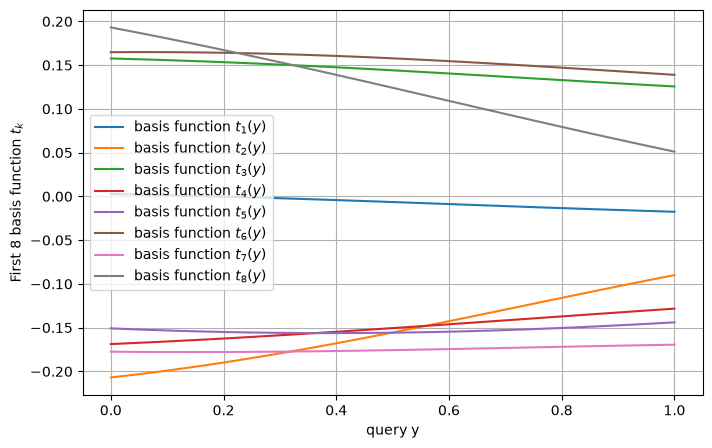

In [198]:
fig, ax = plt.subplots(1,1, figsize=(8,5))
trunk_output = trained_model_2.trunk(Y_train_tensor_expand.unsqueeze(-1)).detach().numpy()
for i in range(8):
    ax.plot(Y_train, trunk_output[1,:,i],label=f'basis function $t_{i+1}(y)$')
ax.grid(True)
ax.set_xlabel('query y')
ax.set_ylabel('First 8 basis function $t_k$')
ax.legend()
plt.show()

**f)** Compare forward pass time vs. finite difference solver time for a single evaluation
### **Answer**

The time for DeepONet forward pass is around 114.3s, while the finite difference solver takes 0.5s

## **3. Physics-Informed DeepONet**